# CSCI 544 Fall 2026: PyTorch Intro
### Original author: Sayan Ghosh (ghoshsay@usc.edu)
This notebook provides an elementary introduction to PyTorch. It goes over Tensors Basics, Autograd, and creating custom modules.

The presented material inspires and sometimes directly borrow from:
*   [Stanford's CS224N PyTorch Tutorial](https://colab.research.google.com/drive/13HGy3-uIIy1KD_WFhG4nVrxJC-3nUUkP?usp=sharing#scrollTo=H6oqGiIXvrMl)
*   [The Annotated Transformer by Sasha Rush](https://nlp.seas.harvard.edu/2018/04/03/attention.html)
* Mozhdeh Gheini's tutorial for 499

## **PyTorch and Tensors Basics**

[PyTorch](https://pytorch.org/) is a deep learning framework, created to streamline the creation and training of neural models.

You'll be using it extensively in your next homeworks and likely your projects.

It takes a bit of time to get used to, but try to just think of it as fancy numpy! That is, all the basic primitives and operations are pretty much directly from numpy, but with some really helpful added features on top.

Let's get started by importing the package.


In [ ]:
import torch
import torch.nn as nn
import numpy as np

The basic datatype in torch is a *tensor*. It is essentially the same as a numpy ndarray

Think of tensors as just multi-dimensional arrays/matrices!

There are multiple ways of initializing tensors

In [ ]:
# creating a tensor
t1 = torch.tensor([1, 2, 3])
print(t1)

tensor([1, 2, 3])


In [ ]:
#creating from numpy
data = [[1, 2], [3, 4]]
data = np.array(data)

t2 = torch.from_numpy(data)
print(t2)

tensor([[1, 2],
        [3, 4]])


Each tensor has elements of a certain data type.

In [ ]:
# looking at a tensor's attributes
print(t1.dtype)
print(t2.dtype)

torch.int64
torch.int64


We can specify the dtype when initializing the tensor as well.

In [ ]:
t3 = torch.tensor([1, 2, 3], dtype=torch.float32)
print(t3)
print(t3.dtype)

tensor([1., 2., 3.])
torch.float32


Another important attribute of a tensor is what *device* it is on (e.g. CPU/GPU). This will become super important later on.



In [ ]:
if torch.cuda.is_available():
  t1 = t1.to('cuda')

print(t1.device)

Checking dimensions is the same as with numpy. (You'll probably be doing this a lot to debug!)

In [ ]:
print(t2.shape)

#another way of doing this
print(t2.size())

torch.Size([2, 2])
torch.Size([2, 2])


Here are some other common ways of initializing and manipulating tensors:

In [ ]:
#We often want to create tensors with a certain shape but
#"placeholder" values

ones_vec = torch.ones(4)
print(ones_vec)

ones_matrix = torch.ones((3, 4))
print(ones_matrix)

#Like numpy, we can also create matrices based
#on a numerical range
range_vec = torch.arange(5)
print(range_vec)

tensor([1., 1., 1., 1.])
tensor([[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]])
tensor([0, 1, 2, 3, 4])


Now let's briefly go over some common manipulations you'll end up doing with tensors:

In [ ]:
m1 = torch.arange(4)
print(m1)

m1 = m1.reshape((2, 2))
print(m1)

m1 = m1.unsqueeze(dim=-1)
print(m1)
print(m1.shape)

m1 = m1.squeeze()
print(m1)
print(m1.shape)

tensor([0, 1, 2, 3])
tensor([[0, 1],
        [2, 3]])
tensor([[[0],
         [1]],

        [[2],
         [3]]])
torch.Size([2, 2, 1])
tensor([[0, 1],
        [2, 3]])
torch.Size([2, 2])


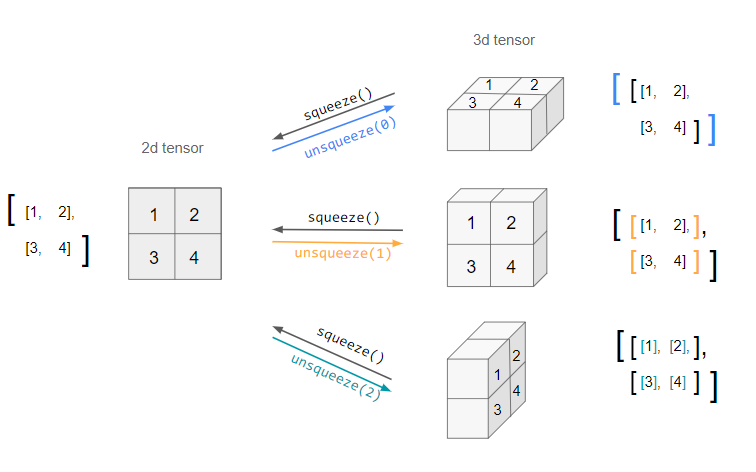

### Exercise 1: Shape warm-up (6 min, with a neighbor)
Make a **float32** tensor holding 0 through 11, reshape it to 3 x 4, then add a batch dimension at the front. Print its shape and dtype.

Expected: `torch.Size([1, 3, 4]) torch.float32`

*Done early?* What does `t.reshape(2, -1)` give, and what does `-1` mean?

In [ ]:
t = torch.arange(12, dtype=torch.float32).reshape(3, 4)
t = t.unsqueeze(0)
print(t.shape, t.dtype)

# print(t.shape, t.dtype)

torch.Size([1, 3, 4]) torch.float32


Like numpy, we can take advantage of being able to perform certain operations over certain axes:

In [ ]:
m2 = torch.arange(1, 21).reshape((4,5))
print(m2)

tensor([[ 1,  2,  3,  4,  5],
        [ 6,  7,  8,  9, 10],
        [11, 12, 13, 14, 15],
        [16, 17, 18, 19, 20]])


In [ ]:
print(m2.sum(dim=0))

tensor([34, 38, 42, 46, 50])


In [ ]:
print(m2.sum(dim=1))

tensor([15, 40, 65, 90])


In [ ]:
print(m2.sum(dim=-1))

tensor([15, 40, 65, 90])


### Broadcasting

[Image and Poem from Sasha Rush](https://www.youtube.com/watch?v=SiwTAyyvt5s)
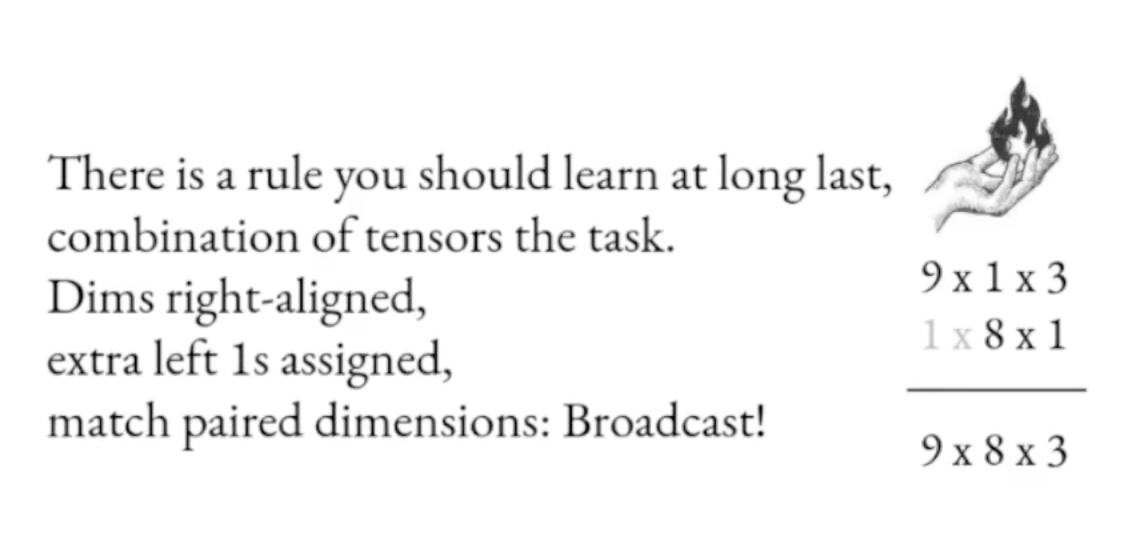

One of the most powerful yet most-misunderstood parts of numpy and torch is broadcasting. It is something you get used to the more you use it.

If you want to become a torch wizard, do these: https://github.com/srush/Tensor-Puzzles

We'll walk through one of these right now.

In [ ]:
# Broadcasting
t4 = torch.arange(24).reshape((3, 8))
print(t4)

to_be_added_to_all = 1
print(t4+to_be_added_to_all)

tensor([[ 0,  1,  2,  3,  4,  5,  6,  7],
        [ 8,  9, 10, 11, 12, 13, 14, 15],
        [16, 17, 18, 19, 20, 21, 22, 23]])
tensor([[ 1,  2,  3,  4,  5,  6,  7,  8],
        [ 9, 10, 11, 12, 13, 14, 15, 16],
        [17, 18, 19, 20, 21, 22, 23, 24]])


In [ ]:
to_be_added_to_each_row = torch.tensor([1, 0, 1, 0, 1, 0, 1, 0])

#let's walk through broadcasting
print(t4+to_be_added_to_each_row)

tensor([[ 1,  1,  3,  3,  5,  5,  7,  7],
        [ 9,  9, 11, 11, 13, 13, 15, 15],
        [17, 17, 19, 19, 21, 21, 23, 23]])


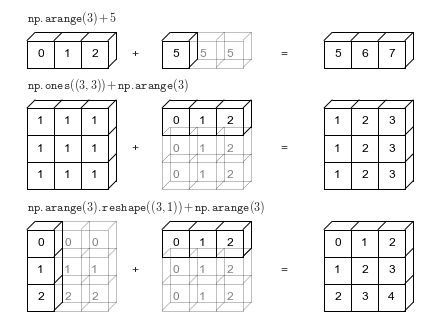

In [ ]:
to_be_added_to_each_column = torch.tensor([1, 2, 3])

# Would this work? Try uncommenting the next line. If not, why, and how can we fix it?
# print(t4 + to_be_added_to_each_column)

print(t4 + to_be_added_to_each_column.reshape(-1, 1))

tensor([[ 1,  2,  3,  4,  5,  6,  7,  8],
        [10, 11, 12, 13, 14, 15, 16, 17],
        [19, 20, 21, 22, 23, 24, 25, 26]])


### Exercise 2: Diagonal of a matrix (8 min, with a neighbor)
Suppose I am given a square (N x N) matrix and I want to write a function to return the *diagonal* of this matrix, without a Python loop.

Expected for the matrix below: `tensor([ 1,  6, 11, 16])`

Hint: `torch.arange`, and indexing with two tensors: `m[[0, 1], [2, 3]]` gives `[m[0, 2], m[1, 3]]`.

*Done early?* Do it with broadcasting and `==` only (no fancy indexing).

In [ ]:
m = torch.arange(1, 17).reshape((4, 4))
print(m)

def diag(m):
  idx = torch.arange(m.shape[0])
  return m[idx, idx]
  # m[[0, 1, 2, 3], [0, 1, 2, 3]] --> m[0, 0], m[1, 1], m[2, 2], m[3, 3]

print(diag(m))

print(diag(m))

tensor([[ 1,  2,  3,  4],
        [ 5,  6,  7,  8],
        [ 9, 10, 11, 12],
        [13, 14, 15, 16]])
tensor([ 1,  6, 11, 16])
tensor([ 1,  6, 11, 16])


In [ ]:
# Stretch: diagonal using only broadcasting and ==
# TODO

## **So this all looked a lot like NumPy. What's all the fuss about then?**

Remember hand-calculating gradients for the quizzes and HW and during lectures; Imagine doing that for a 7B parameter neural network. Thank god for pytorch.

In [ ]:
# Create an example tensor
# requires_grad, another attribute of a tensor instance, tells PyTorch to track
# operations on this tensor so it can compute gradients with respect to it
x = torch.tensor([2.], requires_grad=True)

# Currently None because we haven't called backward() yet
print(x.grad)

None


In [ ]:
y = x * x * 3  # 3x^2
y.backward()   # by calling backward(), everything will be taken care of
print(x.grad)  # d(y)/d(x) = d(3x^2)/d(x) = 6x = 12

tensor([12.])


In [ ]:
z = x * x * 3  # 3x^2 again
z.backward()
print(x.grad)  # tensor([24.]) -> 12 + 12: gradients ACCUMULATE, they don't overwrite

x.grad.zero_() # reset it (the trailing _ means the operation is in-place)
print(x.grad)  # tensor([0.])

tensor([24.])
tensor([0.])


### Exercise 3: Predict the gradient (4 min, no code first!)
```python
x = torch.tensor(3., requires_grad=True)
y = x**3 + 2*x
y.backward()
```
(a) What is `x.grad`?
(b) We recompute `y` the same way and call `y.backward()` again *without* zeroing. Now what?
(c) What happens if `x` didn't have `requires_grad=True`?

Predict with your neighbor, then run the cell below to check.

In [ ]:
x = torch.tensor(3., requires_grad=True)
y = x**3 + 2*x
y.backward()
print("(a)", x.grad)

y = x**3 + 2*x
y.backward()
print("(b)", x.grad)

x_no_grad = torch.tensor(3.)
y = x_no_grad**3 + 2*x_no_grad
try:
    y.backward()
except RuntimeError as e:
    print("(c) RuntimeError:", e)

(a) tensor(29.)
(b) tensor(58.)
(c) RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn


## **How can I use this fancy Autograd stuff?**

It's baked in all instances of torch.nn.module.

Remember implementing the Linear layer in HW2? PyTorch has a module for that!

In [ ]:
# Create the inputs
input = torch.ones(2,4)


# Make a linear layers transforming N,*,H_in dimensinal inputs to N,*,H_out
# dimensional outputs
# y = x * W.t + b
linear = nn.Linear(4, 2)

print(list(linear.parameters()))


linear_output = linear(input)
print(linear_output)

[Parameter containing:
tensor([[ 0.1320, -0.2154,  0.1926, -0.3526],
        [ 0.1093, -0.3172, -0.2333, -0.2915]], requires_grad=True), Parameter containing:
tensor([ 0.2600, -0.3560], requires_grad=True)]
tensor([[ 0.0166, -1.0887],
        [ 0.0166, -1.0887]], grad_fn=<AddmmBackward0>)


In [ ]:
loss = torch.sum(linear_output)
loss.backward()  # backward should be called on a scalar, and loss is always one.

In [ ]:
print(linear.weight.grad)

tensor([[2., 2., 2., 2.],
        [2., 2., 2., 2.]])


In [ ]:
# let's compare it to manual gradient calculation
# torch.ones(2, 2) is the upstream grad (d loss / d output), since loss = sum(output)
# dL/dW = upstream_grad^T @ input
print(torch.ones(2, 2).T @ input)

## **Custom Module**

You can create custom modules by subclassing `nn.Module`. You need to implement `__init__()` and `forward()`. Let's take a look again at the previous HW.

For reference, here is the feed-forward network from the HW2 code (it uses the homework's own classes, so it doesn't run here). Notice we had to write `backward` by hand:

```python
class FeedForwardNetwork(NNComp):
    def __init__(self, in_dim, hidden_dim, n_classes):
        self.fc1 = Linear(in_dim, hidden_dim)
        self.fc2 = Linear(hidden_dim, n_classes)

        self.relu = ReLU()
        self.log_softmax = LogSoftmax()

    def forward(self, x):
        x = self.fc1.forward(x)
        x = self.relu.forward(x)
        x = self.fc2.forward(x)
        x = self.log_softmax.forward(x)
        return x

    def backward(self, incoming_grad):
        grad = self.log_softmax.backward(incoming_grad)
        grad = self.fc2.backward(grad)
        grad = self.relu.backward(grad)
        grad = self.fc1.backward(grad)
        return grad
```

Here's how we would do this in pytorch:

In [ ]:
class SimpleFeedForwardNetwork(nn.Module):
    def __init__(self, in_dim, hidden_dim, n_classes):
        super().__init__()
        self.fc1 = nn.Linear(in_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, n_classes)

        self.relu = nn.ReLU()
        self.log_softmax = nn.LogSoftmax(dim=-1)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        x = self.log_softmax(x)
        return x
        # note: no backward() method -- autograd takes care of it

In [ ]:
model = SimpleFeedForwardNetwork(3, 4, 5)

input = torch.randn(2, 3)   # 2 examples, 3 features each

out = model(input)
print(out.shape)            # torch.Size([2, 5])

torch.Size([2, 5])


Now, let's create a simple single-head self-attention:

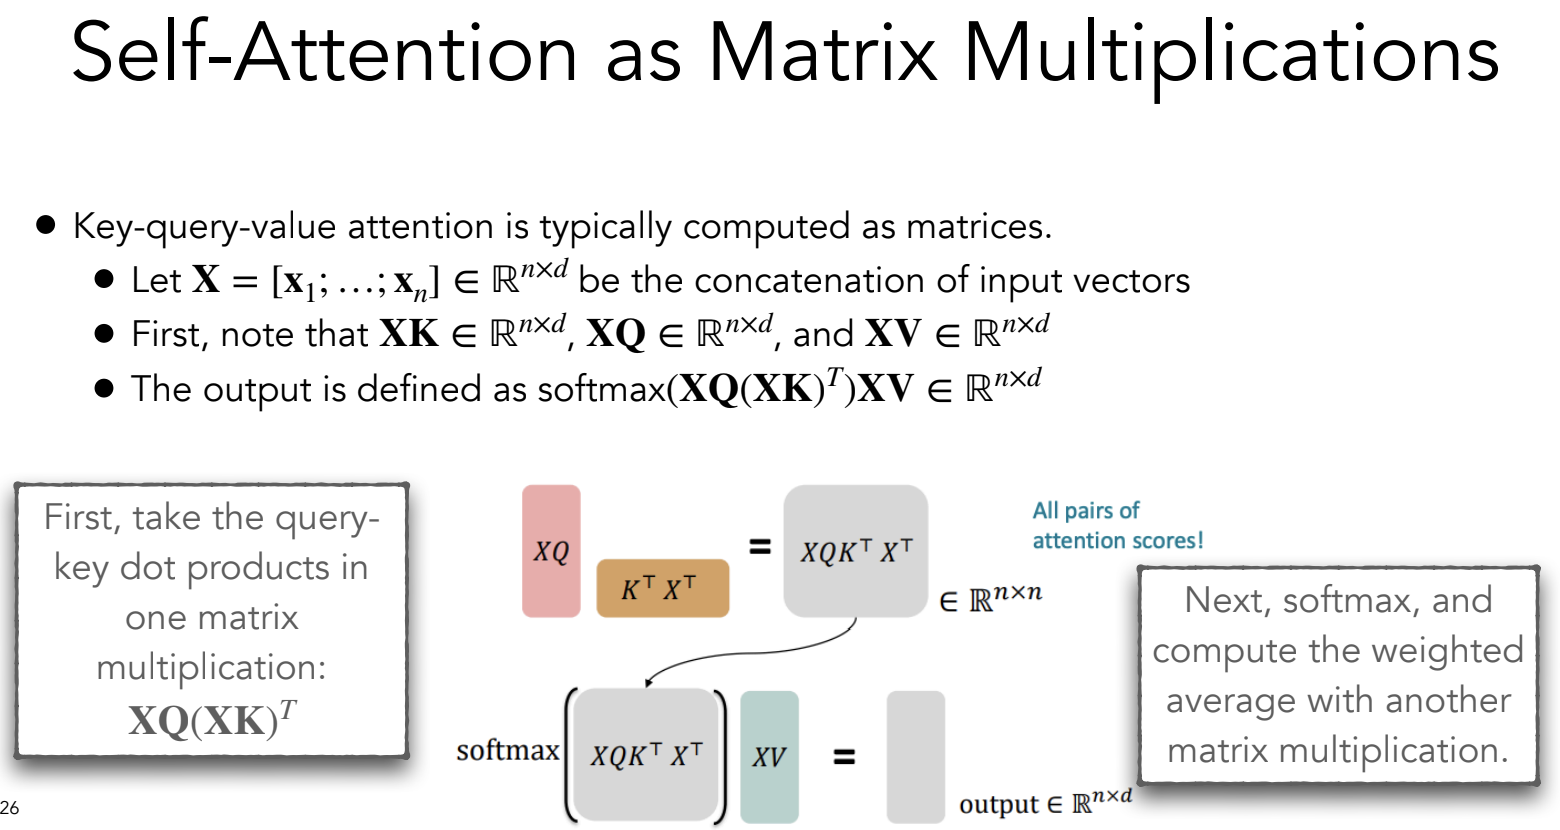

In [ ]:
class SingleSelfAttn(nn.Module):
  def __init__(self, d_model):
    super().__init__()
    self.d_model = d_model

    self.qkv_projectors = nn.ModuleList([nn.Linear(d_model, d_model) for _ in range(3)])

  def forward(self, query, key, value, mask):
    # query, key, value: N * L * d_model
    # mask: None or N * L * L
    q_projection, k_projection, v_projection = [projector(input) for projector, input in zip(self.qkv_projectors, (query, key, value))]
    # Simplified: real scaled dot-product attention also divides scores by sqrt(d_model)
    scores = torch.matmul(q_projection, k_projection.transpose(-2, -1))  # N * L * L
    if mask is not None:
      scores = scores.masked_fill(mask == 0, -1e9)
    attn_weights = nn.Softmax(-1)(scores)  # N * L * L
    return torch.matmul(attn_weights, v_projection)

In [ ]:
!pip install -q torchview

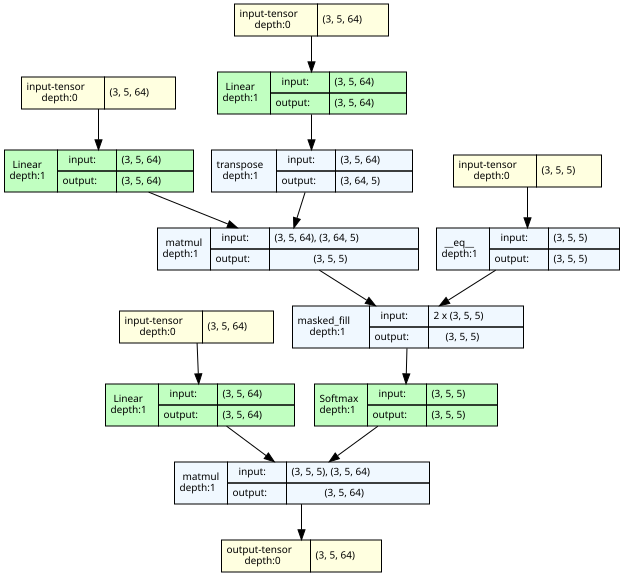

In [ ]:
from torchview import draw_graph

model = SingleSelfAttn(64)
batch_size = 3
seq_len = 5
# device='meta' -> no memory is consumed for visualization
model_graph = draw_graph(model, input_size=[(batch_size, seq_len, 64), (batch_size, seq_len, 64), (batch_size, seq_len, 64), (batch_size, seq_len, seq_len)], device='meta')
model_graph.visual_graph

### Exercise 4: Shape-check the attention layer (7 min, with a neighbor)
Make `SingleSelfAttn(16)`. Create a batch of 2 sequences, length 5, dimension 16. Pass it as query, key and value with `mask=None`. Print the output shape.

Expected: `torch.Size([2, 5, 16])`

*Done early?*
1. How many parameters does the layer have? Predict first, then check with `sum(p.numel() for p in attn.parameters())`.
2. Build a causal mask with `torch.tril` and pass it in.

In [ ]:
attn = SingleSelfAttn(16)
seq = torch.randn(2, 5, 16)
out = attn(seq, seq, seq, None)
print(out.shape)                                    # torch.Size([2, 5, 16])

print(sum(p.numel() for p in attn.parameters()))    # 816 = 3 * (16*16 + 16)

causal = torch.tril(torch.ones(5, 5)).unsqueeze(0)  # (1, 5, 5), broadcasts over the batch
print(causal)
print(attn(seq, seq, seq, causal).shape)            # torch.Size([2, 5, 16])

torch.Size([2, 5, 16])
816
tensor([[[1., 0., 0., 0., 0.],
         [1., 1., 0., 0., 0.],
         [1., 1., 1., 0., 0.],
         [1., 1., 1., 1., 0.],
         [1., 1., 1., 1., 1.]]])
torch.Size([2, 5, 16])


## (If time permits) Optimizers (Credit: 229)

In [ ]:
import torch.optim as optim

First, a small model to train: 5 features down to 3 and back up to 5, ending in a sigmoid so outputs are in [0, 1] (which `BCELoss` needs).

In [ ]:
class MultilayerPerceptron(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, input_size),
            nn.Sigmoid(),
        )

    def forward(self, x):
        return self.model(x)

We can easily create a barebones training loop:

In [ ]:
# Create the y data
y = torch.ones(10, 5)

# Add some noise to our goal y to generate our x
# We want out model to predict our original data, albeit the noise
x = y + torch.randn_like(y)

In [ ]:
# Instantiate the model
model = MultilayerPerceptron(5, 3)

# Define the optimizer
adam = optim.Adam(model.parameters(), lr=1e-1)

# Define loss using a predefined loss function
loss_function = nn.BCELoss()

# Calculate how our model is doing now
y_pred = model(x)
loss_function(y_pred, y).item()

In [ ]:
# Set the number of epoch, which determines the number of training iterations
n_epoch = 10

for epoch in range(n_epoch):
  # 1. Set the gradients to 0
  adam.zero_grad()

  # 2. Get the model predictions
  y_pred = model(x)

  # 3. Get the loss
  loss = loss_function(y_pred, y)

  # Print stats
  print(f"Epoch {epoch}: training loss: {loss.item():.4f}")

  # 4. Compute the gradients
  loss.backward()

  # 5. Take a step to optimize the weights
  adam.step()

# Some Extras

In [ ]:
x = torch.arange(4.0)
x.requires_grad_(True)
y = x * x
u = y.detach()   # same values as y, but cut off from the graph: treated as a constant
z = u * x

z.sum().backward()
x.grad == u      # dz/dx = u, so this is all True